# LoRA SFT for the Child-Facing Chatbot (TRL + PEFT, single T4)

Re-implementation of the original RapidFire experiment without RapidFire.

- **Model**: TinyLlama-1.1B-Chat
- **Data**: `yxpan/children_sft_dataset_v2`: age set by the source (not guessed), 5 balanced age groups, fixed
  train / validation / test splits stratified by age and `needs_knowledge`. The v1 dataset
  (`yxpan/children_sft_dataset`, split by row index) still works: set `DATASET` and `EXP_NAME` back.
- **Configs** (same grid as the experiment report): learning rate {1e-5, 1e-4} x LoRA {r=8 on q,v ; r=32 on all linear layers}
- **Metrics**: BERTScore-F1, ROUGE-L, eval loss / mean token accuracy, training time, and age alignment
  (FKGL readability gap between the model's answer and the reference answer written for that age)
- **Final test**: base model (no SFT) vs best config on the hold-out (test) set, overall, per age group and
  knowledge vs non-knowledge questions

Everything (adapters, metrics, predictions, plots) is saved to Drive. Finished configs are skipped on re-run,
so after a runtime disconnect just run all cells again.

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q -U trl peft evaluate bert_score rouge_score textstat
# Colab ships an old torchao that new PEFT rejects at import time; it is not needed here
!pip uninstall -y -q torchao
# If anything was imported before this cell, restart the session (Runtime -> Restart session) once

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 0. Config

In [ ]:
import os, json, time, gc, random
from collections import Counter
import numpy as np
import torch

BASE_MODEL = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
DATASET = "yxpan/children_sft_dataset_v2"
EXP_NAME = "sft_lora_v2data"  # fixed name so a re-run resumes instead of starting over (v1 data run: "sft_lora_v2")
SEED = 42

MAX_STEPS = 350               # ~2 epochs over the 700 v2 training rows at batch 4 (v1 runs used 256 for 500 rows)
BATCH_SIZE = 4
EVAL_STEPS = 32
MAX_LEN = 1024
N_HOLDOUT = 600               # v1 data only (row-index split); v2 uses its whole test split

# generation settings from the original experiment; seeded so runs are repeatable
GEN_KWARGS = dict(max_new_tokens=128, do_sample=True, temperature=0.8, top_p=0.9, top_k=30,
                  repetition_penalty=1.05)
GEN_BATCH = 16

ATTN_QV = ["q_proj", "v_proj"]
ALL_LINEAR = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
CONFIGS = {
    "baseline": dict(lr=1e-5, r=8,  alpha=4,  targets=ATTN_QV),
    "A":        dict(lr=1e-4, r=8,  alpha=4,  targets=ATTN_QV),
    "B":        dict(lr=1e-5, r=32, alpha=16, targets=ALL_LINEAR),
    "C":        dict(lr=1e-4, r=32, alpha=16, targets=ALL_LINEAR),
    # follow-ups on C, one change each
    "D_lr2e-4":  dict(lr=2e-4, r=32, alpha=16, targets=ALL_LINEAR),               # higher learning rate
    "E_alpha64": dict(lr=1e-4, r=32, alpha=64, targets=ALL_LINEAR),               # LoRA scale alpha/r: 0.5 -> 2
    "F_2xsteps": dict(lr=1e-4, r=32, alpha=16, targets=ALL_LINEAR, steps=2 * MAX_STEPS),  # 2x training steps
}
BEST = None                   # None = pick the SFT config with the highest eval BERT-F1

import transformers
transformers.logging.set_verbosity_error()   # hide the repeated max_length / max_new_tokens notice

In [ ]:
# Save to Drive on Colab, to $OUT_ROOT elsewhere
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = f"/content/drive/MyDrive/llm_sft_runs/{EXP_NAME}"
    TMP_DIR = "/content/tmp_sft"
except ImportError:
    OUT_DIR = os.path.join(os.environ.get("OUT_ROOT", os.path.expanduser("~/llm_sft_runs")), EXP_NAME)
    TMP_DIR = "tmp_sft"
os.makedirs(OUT_DIR, exist_ok=True)

def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=str)

assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU"
import transformers, trl, peft
ENV = dict(gpu=torch.cuda.get_device_name(0), torch=torch.__version__,
           transformers=transformers.__version__, trl=trl.__version__, peft=peft.__version__)
save_json(dict(env=ENV, configs=CONFIGS, max_steps=MAX_STEPS, batch_size=BATCH_SIZE,
               gen_kwargs=GEN_KWARGS, seed=SEED), f"{OUT_DIR}/setup.json")
print(ENV); print("Outputs ->", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'gpu': 'Tesla T4', 'torch': '2.14.1+cu130', 'transformers': '5.22.1', 'trl': '1.18.1', 'peft': '0.21.3'}
Outputs -> /content/drive/MyDrive/llm_sft_runs/sft_lora_v2data


## 1. Data

In [ ]:
from datasets import load_dataset

dsd = load_dataset(DATASET)
if {"train", "validation", "test"} <= set(dsd.keys()):   # v2: fixed stratified splits on the Hub
    train_ds, eval_ds, holdout_ds = dsd["train"], dsd["validation"], dsd["test"]
else:                                                  # v1: a single split, cut by row index
    ds = dsd["train"]
    train_ds = ds.select(range(500)).shuffle(seed=SEED)
    eval_ds = ds.select(range(500, 600)).shuffle(seed=SEED)
    holdout_ds = ds.select(range(600, min(600 + N_HOLDOUT, len(ds))))
print(train_ds.column_names)
for name, d in [("train", train_ds), ("eval", eval_ds), ("hold-out", holdout_ds)]:
    print(f"{name:>8}: {len(d):4d} rows, ages {dict(sorted(Counter(d['age']).items()))}")

def system_prompt(age):
    return (f"You are talking to a child aged {age}. "
            f"Generate a friendly response with age-appropriate knowledge.")

def prompt_messages(row):
    return [{"role": "system", "content": system_prompt(row["age"])},
            {"role": "user", "content": row["instruction"]}]

# prompt-completion format: loss is computed on the assistant answer only
def to_prompt_completion(row):
    return {"prompt": prompt_messages(row),
            "completion": [{"role": "assistant", "content": row["response"]}]}

train_pc = train_ds.map(to_prompt_completion, remove_columns=train_ds.column_names)
eval_pc = eval_ds.map(to_prompt_completion, remove_columns=eval_ds.column_names)
EVAL_ROWS, HOLDOUT_ROWS = list(eval_ds), list(holdout_ds)
train_pc[0]

['id', 'age', 'intent', 'needs_knowledge', 'instruction', 'response', 'source', 'age_source', 'origin', 'fkgl']
   train:  700 rows, ages {'0-3': 140, '10-13': 140, '14-18': 140, '4-6': 140, '7-9': 140}
    eval:  100 rows, ages {'0-3': 20, '10-13': 20, '14-18': 20, '4-6': 20, '7-9': 20}
hold-out:  393 rows, ages {'0-3': 77, '10-13': 79, '14-18': 80, '4-6': 77, '7-9': 80}


{'prompt': [{'content': 'You are talking to a child aged 10-13. Generate a friendly response with age-appropriate knowledge.',
   'role': 'system'},
  {'content': 'Why do we have a heart?', 'role': 'user'}],
 'completion': [{'content': 'Your heart is like a super-powered pump! Its main job is to push blood all through your body, delivering oxygen and nutrients to your muscles and organs so they have the energy to work and grow.',
   'role': 'assistant'}]}

## 2. Evaluation helpers

- **BERTScore-F1 / ROUGE-L**: model answer vs reference answer
- **Age alignment**: the reference answers were written for each child's age, so their readability is the target.
  `fkgl_gap` = mean |FKGL(model answer) - FKGL(reference)| in grade levels (lower is better);
  `fkgl_within2` = share of answers within 2 grade levels of the reference (higher is better).

In [ ]:
import evaluate, textstat
from transformers import AutoModelForCausalLM, AutoTokenizer

tok = AutoTokenizer.from_pretrained(BASE_MODEL)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

rouge = evaluate.load("rouge")
bertscore = evaluate.load("bertscore")

@torch.no_grad()
def generate(model, rows):
    tok.padding_side = "left"
    torch.manual_seed(SEED)
    preds = []
    for i in range(0, len(rows), GEN_BATCH):
        texts = [tok.apply_chat_template(prompt_messages(r), tokenize=False, add_generation_prompt=True)
                 for r in rows[i:i + GEN_BATCH]]
        enc = tok(texts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        out = model.generate(**enc, **GEN_KWARGS, pad_token_id=tok.pad_token_id)
        preds += tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    tok.padding_side = "right"
    return [p.strip() for p in preds]

def fkgl(text):
    return textstat.flesch_kincaid_grade(text) if text.strip() else np.nan

def text_metrics(preds, rows):
    refs = [r["response"] for r in rows]
    bert = bertscore.compute(predictions=preds, references=refs, lang="en", batch_size=32)["f1"]
    gap = np.abs(np.array([fkgl(p) for p in preds]) - np.array([fkgl(t) for t in refs]))
    return dict(bert_f1=float(np.mean(bert)),
                rougeL=float(rouge.compute(predictions=preds, references=refs)["rougeL"]),
                fkgl_gap=float(np.nanmean(gap)),
                fkgl_within2=float(np.nanmean(gap <= 2)),
                empty_frac=float(np.mean([not p for p in preds])))

def per_knowledge(preds, rows):
    if "needs_knowledge" not in rows[0]:
        return {}
    out = {}
    for flag, label in [(True, "knowledge"), (False, "non-knowledge")]:
        idx = [i for i, r in enumerate(rows) if bool(r["needs_knowledge"]) == flag]
        out[label] = dict(n=len(idx), **text_metrics([preds[i] for i in idx], [rows[i] for i in idx]))
    return out

def per_age(preds, rows):
    out = {}
    for age in sorted(set(r["age"] for r in rows)):
        idx = [i for i, r in enumerate(rows) if r["age"] == age]
        out[age] = dict(n=len(idx), **text_metrics([preds[i] for i in idx], [rows[i] for i in idx]))
    return out

def save_preds(preds, rows, path):
    with open(path, "w") as f:
        for p, r in zip(preds, rows):
            f.write(json.dumps(dict(age=r["age"], instruction=r["instruction"],
                                    reference=r["response"], prediction=p)) + "\n")

def load_base():
    return AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.float16).to("cuda").eval()

def free(*objs):
    for o in objs:
        del o
    gc.collect(); torch.cuda.empty_cache()

## 3. Base model (no SFT) on the eval set

In [ ]:
base_path = f"{OUT_DIR}/base/metrics.json"
if os.path.exists(base_path):
    print("skip, already done"); BASE_METRICS = json.load(open(base_path))
else:
    os.makedirs(f"{OUT_DIR}/base", exist_ok=True)
    model = load_base()
    preds = generate(model, EVAL_ROWS)
    BASE_METRICS = dict(config="base (no SFT)", **text_metrics(preds, EVAL_ROWS))
    save_preds(preds, EVAL_ROWS, f"{OUT_DIR}/base/eval_preds.jsonl")
    save_json(BASE_METRICS, base_path)
    free(model)
print(BASE_METRICS)

skip, already done
{'config': 'base (no SFT)', 'bert_f1': 0.8527061289548874, 'rougeL': 0.14446899131378746, 'fkgl_gap': 3.1343787848696456, 'fkgl_within2': 0.41, 'empty_frac': 0.0}


## 4. Train the four LoRA configs

In [ ]:
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

def train_one(name, cfg):
    run_dir = f"{OUT_DIR}/{name}"
    adapter_file = f"{run_dir}/adapter/adapter_model.safetensors"
    if (os.path.exists(f"{run_dir}/metrics.json") and os.path.exists(adapter_file)
            and os.path.getsize(adapter_file) > 0):   # both, in case a disconnect lost the adapter upload
        print(f"[{name}] skip, already done")
        return json.load(open(f"{run_dir}/metrics.json"))
    os.makedirs(run_dir, exist_ok=True)

    model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.float16).to("cuda")
    peft_cfg = LoraConfig(r=cfg["r"], lora_alpha=cfg["alpha"], lora_dropout=0.1,
                          target_modules=cfg["targets"], bias="none", task_type="CAUSAL_LM")
    args = SFTConfig(output_dir=f"{TMP_DIR}/{name}", learning_rate=cfg["lr"], lr_scheduler_type="linear",
                     per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
                     max_steps=cfg.get("steps", MAX_STEPS), logging_steps=8, eval_strategy="steps", eval_steps=EVAL_STEPS,
                     save_strategy="no", fp16=True, bf16=False, max_length=MAX_LEN, seed=SEED, report_to="none")
    trainer = SFTTrainer(model=model, args=args, train_dataset=train_pc, eval_dataset=eval_pc,
                         processing_class=tok, peft_config=peft_cfg)
    n_trainable = sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)

    t0 = time.time(); trainer.train(); train_min = (time.time() - t0) / 60
    ev = trainer.evaluate()
    trainer.model.save_pretrained(f"{run_dir}/adapter")
    tok.save_pretrained(f"{run_dir}/adapter")
    save_json(trainer.state.log_history, f"{run_dir}/log_history.json")

    m = trainer.model.eval(); m.config.use_cache = True
    preds = generate(m, EVAL_ROWS)
    save_preds(preds, EVAL_ROWS, f"{run_dir}/eval_preds.jsonl")
    metrics = dict(config=name, lr=cfg["lr"], r=cfg["r"], alpha=cfg["alpha"], steps=cfg.get("steps", MAX_STEPS),
                   targets="all linear" if cfg["targets"] == ALL_LINEAR else ",".join(cfg["targets"]),
                   trainable_params=n_trainable, train_min=round(train_min, 2),
                   eval_loss=ev.get("eval_loss"), eval_token_acc=ev.get("eval_mean_token_accuracy"),
                   **text_metrics(preds, EVAL_ROWS))
    save_json(metrics, f"{run_dir}/metrics.json")
    free(trainer, model, m)
    print(f"[{name}]", metrics)
    return metrics

RESULTS = {name: train_one(name, cfg) for name, cfg in CONFIGS.items()}

[baseline] skip, already done
[A] skip, already done
[B] skip, already done
[C] skip, already done


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'loss': '2.017', 'grad_norm': '0.688', 'learning_rate': '0.000196', 'entropy': '1.514', 'mean_token_accuracy': '0.5452', 'num_tokens': '4760', 'epoch': '0.04571'}
{'loss': '1.661', 'grad_norm': '0.5212', 'learning_rate': '0.0001914', 'entropy': '1.606', 'mean_token_accuracy': '0.5809', 'num_tokens': '9388', 'epoch': '0.09143'}
{'loss': '1.679', 'grad_norm': '0.5893', 'learning_rate': '0.0001869', 'entropy': '1.706', 'mean_token_accuracy': '0.5815', 'num_tokens': '1.389e+04', 'epoch': '0.1371'}
{'loss': '1.717', 'grad_norm': '0.6706', 'learning_rate': '0.0001823', 'entropy': '1.765', 'mean_token_accuracy': '0.5803', 'num_tokens': '1.795e+04', 'epoch': '0.1829'}
{'eval_loss': '1.64', 'eval_runtime': '7.108', 'eval_samples_per_second': '14.07', 'eval_steps_per_second': '3.517', 'eval_entropy': '1.714', 'eval_mean_token_accuracy': '0.5887', 'eval_num_tokens': '1.795e+04', 'epoch': '0.1829'}
{'loss': '1.766', 'grad_norm': '0.6267', 'learning_rate': '0.0001777', 'entropy': '1.753', 'mean_to

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[D_lr2e-4] {'config': 'D_lr2e-4', 'lr': 0.0002, 'r': 32, 'alpha': 16, 'steps': 350, 'targets': 'all linear', 'trainable_params': 25231360, 'train_min': 5.98, 'eval_loss': 1.5289503335952759, 'eval_token_acc': 0.6137976098060608, 'bert_f1': 0.8761245709657669, 'rougeL': 0.20406257137007644, 'fkgl_gap': 2.235280950089652, 'fkgl_within2': 0.56, 'empty_frac': 0.0}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'loss': '1.87', 'grad_norm': '2.062', 'learning_rate': '9.8e-05', 'entropy': '1.581', 'mean_token_accuracy': '0.5558', 'num_tokens': '4760', 'epoch': '0.04571'}
{'loss': '1.631', 'grad_norm': '1.663', 'learning_rate': '9.571e-05', 'entropy': '1.685', 'mean_token_accuracy': '0.5823', 'num_tokens': '9388', 'epoch': '0.09143'}
{'loss': '1.656', 'grad_norm': '1.88', 'learning_rate': '9.343e-05', 'entropy': '1.658', 'mean_token_accuracy': '0.5907', 'num_tokens': '1.389e+04', 'epoch': '0.1371'}
{'loss': '1.691', 'grad_norm': '2.048', 'learning_rate': '9.114e-05', 'entropy': '1.723', 'mean_token_accuracy': '0.5823', 'num_tokens': '1.795e+04', 'epoch': '0.1829'}
{'eval_loss': '1.626', 'eval_runtime': '4.927', 'eval_samples_per_second': '20.3', 'eval_steps_per_second': '5.074', 'eval_entropy': '1.693', 'eval_mean_token_accuracy': '0.5963', 'eval_num_tokens': '1.795e+04', 'epoch': '0.1829'}
{'loss': '1.752', 'grad_norm': '1.897', 'learning_rate': '8.886e-05', 'entropy': '1.743', 'mean_token_acc

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'loss': '2.09', 'grad_norm': '0.9452', 'learning_rate': '9.9e-05', 'entropy': '1.482', 'mean_token_accuracy': '0.539', 'num_tokens': '4760', 'epoch': '0.04571'}
{'loss': '1.705', 'grad_norm': '0.661', 'learning_rate': '9.786e-05', 'entropy': '1.46', 'mean_token_accuracy': '0.5745', 'num_tokens': '9388', 'epoch': '0.09143'}
{'loss': '1.719', 'grad_norm': '0.5619', 'learning_rate': '9.671e-05', 'entropy': '1.588', 'mean_token_accuracy': '0.5771', 'num_tokens': '1.389e+04', 'epoch': '0.1371'}
{'loss': '1.759', 'grad_norm': '0.6452', 'learning_rate': '9.557e-05', 'entropy': '1.772', 'mean_token_accuracy': '0.5684', 'num_tokens': '1.795e+04', 'epoch': '0.1829'}
{'eval_loss': '1.67', 'eval_runtime': '4.947', 'eval_samples_per_second': '20.21', 'eval_steps_per_second': '5.054', 'eval_entropy': '1.752', 'eval_mean_token_accuracy': '0.5867', 'eval_num_tokens': '1.795e+04', 'epoch': '0.1829'}
{'loss': '1.799', 'grad_norm': '0.6152', 'learning_rate': '9.443e-05', 'entropy': '1.809', 'mean_token_

## 5. Compare configs

,lr,r,alpha,steps,targets,trainable_params,train_min,eval_loss,eval_token_acc,bert_f1,rougeL,fkgl_gap,fkgl_within2,empty_frac
config,,,,,,,,,,,,,,
base (no SFT),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.8527,0.1445,3.1344,0.41,0.0
baseline,0.0000,8.0,4.0,350.0,"q_proj,v_proj",1126400.0,3.05,1.9293,0.5470,0.8562,0.1577,3.0083,0.42,0.0
A,0.0001,8.0,4.0,350.0,"q_proj,v_proj",1126400.0,3.17,1.6566,0.5888,0.8709,0.1832,2.6273,0.45,0.0
B,0.0000,32.0,16.0,350.0,all linear,25231360.0,4.35,1.6768,0.5844,0.8720,0.1842,2.6143,0.49,0.0
C,0.0001,32.0,16.0,350.0,all linear,25231360.0,4.34,1.5414,0.6120,0.8764,0.2117,2.0979,0.50,0.0
D_lr2e-4,0.0002,32.0,16.0,350.0,all linear,25231360.0,5.98,1.5290,0.6138,0.8761,0.2041,2.2353,0.56,0.0
E_alpha64,0.0001,32.0,64.0,350.0,all linear,25231360.0,4.39,1.5307,0.6123,0.8770,0.2054,2.0154,0.57,0.0
F_2xsteps,0.0001,32.0,16.0,700.0,all linear,25231360.0,8.76,1.6134,0.6015,0.8791,0.2141,2.0336,0.55,0.0


best config: F_2xsteps


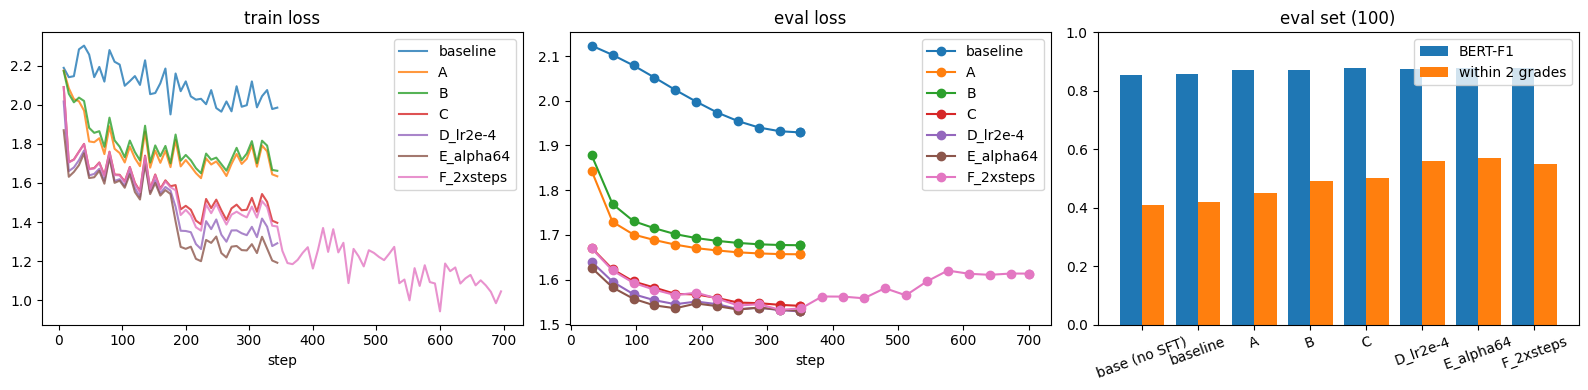

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

table = pd.DataFrame([BASE_METRICS] + list(RESULTS.values())).set_index("config")
cols = ["lr", "r", "alpha", "steps", "targets", "trainable_params", "train_min", "eval_loss", "eval_token_acc",
        "bert_f1", "rougeL", "fkgl_gap", "fkgl_within2", "empty_frac"]
table = table[[c for c in cols if c in table.columns]]
display(table.round(4))
table.to_csv(f"{OUT_DIR}/config_comparison.csv")

if BEST is None:
    BEST = max(RESULTS, key=lambda k: RESULTS[k]["bert_f1"])
print("best config:", BEST)
save_json(dict(best=BEST, selected_by="eval bert_f1"), f"{OUT_DIR}/best_config.json")  # read by the GRPO notebook

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name in CONFIGS:
    hist = json.load(open(f"{OUT_DIR}/{name}/log_history.json"))
    tr = [(h["step"], h["loss"]) for h in hist if "loss" in h]
    ev = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]
    axes[0].plot(*zip(*tr), label=name, alpha=0.8)
    axes[1].plot(*zip(*ev), "o-", label=name)
axes[0].set_title("train loss"); axes[1].set_title("eval loss")
for ax in axes[:2]:
    ax.set_xlabel("step"); ax.legend()
names = list(table.index)
x = np.arange(len(names))
axes[2].bar(x - 0.2, table["bert_f1"], 0.4, label="BERT-F1")
axes[2].bar(x + 0.2, table["fkgl_within2"], 0.4, label="within 2 grades")
axes[2].set_xticks(x, names, rotation=20); axes[2].set_ylim(0, 1); axes[2].legend()
axes[2].set_title("eval set (100)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/config_comparison.png", dpi=150); plt.show()

## 6. Final test: base vs best config on the hold-out set

The hold-out rows were never used for training or for choosing the config.

In [ ]:
from peft import PeftModel

final_path = f"{OUT_DIR}/holdout_{BEST}.json"
if os.path.exists(final_path):
    print("skip, already done"); FINAL = json.load(open(final_path))
else:
    FINAL = {}
    model = load_base()
    preds = generate(model, HOLDOUT_ROWS)
    save_preds(preds, HOLDOUT_ROWS, f"{OUT_DIR}/base/holdout_preds.jsonl")
    FINAL["base"] = dict(overall=text_metrics(preds, HOLDOUT_ROWS), per_age=per_age(preds, HOLDOUT_ROWS),
                         per_knowledge=per_knowledge(preds, HOLDOUT_ROWS))
    save_json(FINAL, final_path + ".partial")

    model = PeftModel.from_pretrained(model, f"{OUT_DIR}/{BEST}/adapter").eval()
    preds = generate(model, HOLDOUT_ROWS)
    save_preds(preds, HOLDOUT_ROWS, f"{OUT_DIR}/{BEST}/holdout_preds.jsonl")
    FINAL[BEST] = dict(overall=text_metrics(preds, HOLDOUT_ROWS), per_age=per_age(preds, HOLDOUT_ROWS),
                       per_knowledge=per_knowledge(preds, HOLDOUT_ROWS))
    save_json(FINAL, final_path)
    free(model)

b, s = FINAL["base"]["overall"], FINAL[BEST]["overall"]
summary = pd.DataFrame({"base": b, BEST: s}).T
summary.loc["relative change"] = [(s[k] - b[k]) / b[k] if b[k] else np.nan for k in summary.columns]
display(summary.round(4))
summary.to_csv(f"{OUT_DIR}/holdout_summary.csv")

rows = []
for age in FINAL["base"]["per_age"]:
    rb, rs = FINAL["base"]["per_age"][age], FINAL[BEST]["per_age"][age]
    rows.append(dict(age=age, n=rb["n"], bert_f1_base=rb["bert_f1"], bert_f1_sft=rs["bert_f1"],
                     fkgl_gap_base=rb["fkgl_gap"], fkgl_gap_sft=rs["fkgl_gap"],
                     within2_base=rb["fkgl_within2"], within2_sft=rs["fkgl_within2"]))
by_age = pd.DataFrame(rows).set_index("age")
display(by_age.round(3))
by_age.to_csv(f"{OUT_DIR}/holdout_by_age.csv")

if FINAL["base"].get("per_knowledge"):
    by_kn = pd.DataFrame([dict(group=g, n=FINAL["base"]["per_knowledge"][g]["n"],
                               **{f"{m}_{who}": FINAL[key]["per_knowledge"][g][m]
                                  for m in ("bert_f1", "fkgl_gap", "fkgl_within2")
                                  for who, key in (("base", "base"), ("sft", BEST))})
                          for g in FINAL["base"]["per_knowledge"]]).set_index("group")
    display(by_kn.round(3))
    by_kn.to_csv(f"{OUT_DIR}/holdout_by_knowledge.csv")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,bert_f1,rougeL,fkgl_gap,fkgl_within2,empty_frac
base,0.8538,0.1520,3.1151,0.3919,0.0
F_2xsteps,0.8804,0.2198,1.9257,0.5980,0.0
relative change,0.0310,0.4460,-0.3818,0.5260,NaN


,n,bert_f1_base,bert_f1_sft,fkgl_gap_base,fkgl_gap_sft,within2_base,within2_sft
age,,,,,,,
0-3,77,0.840,0.888,4.199,1.887,0.273,0.597
10-13,79,0.861,0.876,2.464,1.864,0.494,0.582
14-18,80,0.858,0.870,2.515,2.434,0.475,0.500
4-6,77,0.847,0.883,3.239,1.722,0.377,0.636
7-9,80,0.863,0.885,3.196,1.712,0.338,0.675


,n,bert_f1_base,bert_f1_sft,fkgl_gap_base,fkgl_gap_sft,fkgl_within2_base,fkgl_within2_sft
group,,,,,,,
knowledge,192,0.862,0.883,3.249,1.964,0.370,0.589
non-knowledge,201,0.846,0.878,2.988,1.889,0.413,0.607


## 7. Adapter for the serving benchmark

In [ ]:
ADAPTER_PATH = f"{OUT_DIR}/{BEST}/adapter"
print("Set ADAPTER_PATH in vllm_serving_benchmark.ipynb to:\n ", ADAPTER_PATH)
# Optional: push to the Hugging Face Hub so other notebooks / machines can load it by name
# from huggingface_hub import login; login()
# PeftModel.from_pretrained(load_base(), ADAPTER_PATH).push_to_hub("yxpan/tinyllama-child-sft-lora")

Set ADAPTER_PATH in vllm_serving_benchmark.ipynb to:
  /content/drive/MyDrive/llm_sft_runs/sft_lora_v2data/F_2xsteps/adapter
